# Pull × Air Quadrant Model — Frontier League (PAA + PAD Edition)

Recreates the MLB Pull × Air quadrant analysis on FL data, with the bat-tracking swing
features (`mean_tilt`, `mean_aa`, `mean_dir`) replaced by the envelope-derived
**Preferred Attack Angle (PAA)** and **Preferred Attack Direction (PAD)**.
Swing Path Tilt is excluded (no FL bat tracking). Contact-point diagnostics are
excluded (no intercept data). Everything else runs at the **batter-year** level.

**Pipeline**
1. FL BBE pull (validated conventions: `pitch_call='in_play'`, ±45° direction filter,
   assert-mapped handedness, `'undefined'` rows dropped)
2. Pull / Air flags (±15° mirrored spray, LA ≥ 10)
3. Batter-year aggregation: Pull%, Air%, PullAir%, EV metrics, wOBAcon
4. PAA + PAD per batter-year (Marshall envelope method)
5. Quadrant assignment via median splits → Neither / Pull only / Air only / Both
6. Correlations: PAA & PAD vs the marginals and the joint
7. Multinomial quadrant classifiers (LR + interaction, RF) with **GroupKFold by batter**
8. Direct Pull Air% regression + compression check
9. wOBAcon by quadrant (weighted, with error bars)
10. Year-over-year stickiness: PullAir%, PAA, PAD
11. Final deliverable table

## 1. Imports & Config

In [33]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from scipy.stats import spearmanr, f_oneway, kruskal
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                             cohen_kappa_score, accuracy_score, r2_score)

pd.set_option("display.max_columns", 80)
pd.set_option("display.float_format", "{:.3f}".format)

# ── Validated FL conventions ──────────────────────────────────────────────────
PULL_CUTOFF_DEG = 15          # reproduces ≈.36 league Pull%
AIR_LA_MIN      = 10          # LD/FB/PU
DIR_RANGE       = (-45, 45)   # physical spray window

# ── Envelope (Marshall) parameters — same as PAA/PAD notebooks ────────────────
ANGLE_MIN, ANGLE_MAX = -30, 60
SPRAY_MIN, SPRAY_MAX = -45, 45
BIN_WIDTH        = 3
TOP_FRAC_PER_BIN = 0.20
TOP_N_METHOD2    = 15

# ── Qualification ─────────────────────────────────────────────────────────────
MIN_BBE = 100                 # per batter-year (FL season ≈ 96 games)

QUAD_ORDER  = ["Neither", "Pull only", "Air only", "Both"]
QUAD_COLORS = {"Neither": "#9E9E9E", "Pull only": "#E65100",
               "Air only": "#1565C0", "Both": "#1B5E20"}

print("Config OK")

Config OK


## 2. PAA + PAD — Envelope Functions

In [34]:
def _envelope_peak(g, x_col, ev_col, x_min, x_max):
    """Shared Marshall machinery: envelope parabola peak + top-15 mean on axis x."""
    g = g.dropna(subset=[x_col, ev_col])
    g = g[(g[x_col] >= x_min) & (g[x_col] <= x_max)]
    if len(g) < 10:
        return np.nan, np.nan, np.nan, 0

    k2 = min(TOP_N_METHOD2, max(3, int(np.ceil(0.2 * len(g)))))
    method2 = g.nlargest(k2, ev_col)[x_col].mean()

    bins = np.arange(x_min, x_max + BIN_WIDTH, BIN_WIDTH)
    g = g.copy()
    g["_bin"] = pd.cut(g[x_col], bins=bins, include_lowest=True)

    env_idx = []
    for _, grp in g.groupby("_bin", observed=True):
        if len(grp) == 0:
            continue
        k = max(1, int(np.ceil(TOP_FRAC_PER_BIN * len(grp))))
        env_idx.extend(grp.nlargest(k, ev_col).index)
    env = g.loc[env_idx]
    if len(env) < 5:
        return method2, np.nan, method2, len(env)

    a, b, c = np.polyfit(env[x_col], env[ev_col], deg=2)
    if a < 0:
        v = -b / (2 * a)
        if x_min <= v <= x_max:
            method1 = v
        else:
            xs = np.linspace(x_min, x_max, 361)
            method1 = xs[np.argmax(np.polyval([a, b, c], xs))]
    else:
        method1 = env.loc[env[ev_col].idxmax(), x_col]

    return np.nanmean([method1, method2]), method1, method2, len(env)


def paa_of(g):  # Preferred Attack Angle (vertical)
    return _envelope_peak(g, "angle", "exit_speed", ANGLE_MIN, ANGLE_MAX)[0]

def pad_of(g):  # Preferred Attack Direction (horizontal, pull-positive)
    return _envelope_peak(g, "spray_pull", "exit_speed", SPRAY_MIN, SPRAY_MAX)[0]

print("Envelope functions defined")

Envelope functions defined


## 3. FL Pull — BBE with Outcomes

In [35]:
ENV_PATH = r"C:/Users/215nt/PycharmProjects/FLStuff/FLPitching/FLCommand/.env"

def get_engine():
    load_dotenv(ENV_PATH)
    host     = os.getenv("SUPABASE_HOST", "aws-1-us-east-1.pooler.supabase.com")
    port     = os.getenv("SUPABASE_PORT", "6543")
    dbname   = os.getenv("SUPABASE_DB",   "postgres")
    user     = os.getenv("SUPABASE_USER")
    password = os.getenv("SUPABASE_PASSWORD")
    return create_engine(
        f"postgresql+psycopg2://{user}:{password}@{host}:{port}/{dbname}?sslmode=require"
    )

SQL = """
SELECT
    batter,
    batter_team,
    batter_side,
    year,
    exit_speed,
    angle,
    direction,
    play_result
FROM pitches
WHERE pitch_call = 'in_play'
  AND exit_speed IS NOT NULL
  AND angle      IS NOT NULL
  AND direction  IS NOT NULL
  AND batter     IS NOT NULL
"""

engine = get_engine()
with engine.connect() as conn:
    fl_raw = pd.read_sql(text(SQL), conn)

print(f"FL BBE rows: {len(fl_raw):,}   batters: {fl_raw['batter'].nunique()}")
print(f"Years: {sorted(fl_raw['year'].unique())}")
print("\nplay_result values (verify hit categories map correctly):")
print(fl_raw["play_result"].value_counts(dropna=False))

FL BBE rows: 65,940   batters: 585
Years: [np.float64(2025.0), np.float64(2026.0), np.float64(nan)]

play_result values (verify hit categories map correctly):
play_result
out                38730
single             15812
double              4241
home_run            2334
fielders_choice     1767
error               1413
sacrifice           1270
triple               367
undefined              6
Name: count, dtype: int64


## 4. Conventions, Flags & wOBAcon Weights

In [36]:
FL_HAND_MAP = {"Left": "L", "Right": "R", "left": "L", "right": "R"}

n0 = len(fl_raw)
fl = fl_raw[fl_raw["batter_side"] != "undefined"].copy()
print(f"Dropped {n0 - len(fl):,} rows with undefined batter_side")

unmapped = fl.loc[~fl["batter_side"].isin(FL_HAND_MAP), "batter_side"].unique()
assert len(unmapped) == 0, f"Unmapped batter_side values: {list(unmapped)}"
fl["stand"] = fl["batter_side"].map(FL_HAND_MAP)

n0 = len(fl)
fl = fl[fl["direction"].between(*DIR_RANGE)].copy()
print(f"Direction filter: dropped {n0 - len(fl):,} rows")

# Mirrored spray: pull-positive both hands (validated convention)
fl["spray_pull"] = np.where(fl["stand"] == "R", -fl["direction"], fl["direction"])
fl["is_pull"]    = fl["spray_pull"] > PULL_CUTOFF_DEG
fl["is_air"]     = fl["angle"] >= AIR_LA_MIN
fl["pull_air"]   = fl["is_pull"] & fl["is_air"]
fl["hard_hit"]   = fl["exit_speed"] >= 95

print(f"\nFL league Pull%    : {fl['is_pull'].mean():.3f}   (expect ≈ .36)")
print(f"FL league Air%     : {fl['is_air'].mean():.3f}")
print(f"FL league PullAir% : {fl['pull_air'].mean():.3f}")

# ── wOBAcon: contact-only wOBA using standard linear weights ──────────────────
# Normalize play_result case; anything not a hit contributes 0 (out/error/FC/sac)
WOBA_W = {"single": 0.88, "double": 1.25, "triple": 1.58,
          "homerun": 2.03, "home_run": 2.03}
fl["pr_norm"]  = fl["play_result"].astype(str).str.lower().str.replace(" ", "")
fl["woba_val"] = fl["pr_norm"].map(WOBA_W).fillna(0.0)

mapped_hits = fl.loc[fl["woba_val"] > 0, "pr_norm"].value_counts()
print("\nHit categories mapped for wOBAcon:")
print(mapped_hits)
assert len(mapped_hits) >= 3, "Hit categories not mapping — check play_result values above"


Dropped 25 rows with undefined batter_side
Direction filter: dropped 4,348 rows

FL league Pull%    : 0.361   (expect ≈ .36)
FL league Air%     : 0.565
FL league PullAir% : 0.157

Hit categories mapped for wOBAcon:
pr_norm
single      15280
double       4157
home_run     2333
triple        366
Name: count, dtype: int64


## 5. Batter-Year Aggregation + PAA / PAD

In [37]:
grp = fl.groupby(["batter", "year"])

batter_df = grp.agg(
    n_bbe        = ("exit_speed", "size"),
    pull_pct     = ("is_pull",   "mean"),
    air_ball_pct = ("is_air",    "mean"),
    pull_air_pct = ("pull_air",  "mean"),
    mean_ev      = ("exit_speed","mean"),
    ev_90        = ("exit_speed", lambda s: s.quantile(0.90)),
    hard_hit_pct = ("hard_hit",  "mean"),
    wOBAcon      = ("woba_val",  "mean"),
    stand        = ("stand", lambda s: s.mode().iloc[0]),
).reset_index()

# PAA + PAD per batter-year (envelope method — slower, one fit per group)
paa_vals, pad_vals = [], []
for (b, y), g in grp:
    paa_vals.append({"batter": b, "year": y, "PAA": paa_of(g)})
    pad_vals.append({"batter": b, "year": y, "PAD": pad_of(g)})
batter_df = (batter_df
             .merge(pd.DataFrame(paa_vals), on=["batter", "year"])
             .merge(pd.DataFrame(pad_vals), on=["batter", "year"]))

batter_df["is_L"] = (batter_df["stand"] == "L").astype(int)

qual = batter_df[(batter_df["n_bbe"] >= MIN_BBE) &
                 batter_df["PAA"].notna() &
                 batter_df["PAD"].notna()].copy()

print(f"Batter-years total: {len(batter_df)}   qualified (≥{MIN_BBE} BBE): {len(qual)}")
print(f"Unique qualified batters: {qual['batter'].nunique()}")
print(qual[["PAA", "PAD", "pull_pct", "air_ball_pct", "pull_air_pct"]].describe().round(3))

Batter-years total: 711   qualified (≥100 BBE): 265
Unique qualified batters: 207
          PAA     PAD  pull_pct  air_ball_pct  pull_air_pct
count 265.000 265.000   265.000       265.000       265.000
mean   13.531  11.456     0.363         0.567         0.160
std     4.949   6.243     0.078         0.079         0.062
min    -5.576 -11.192     0.144         0.367         0.019
25%    10.412   8.351     0.312         0.515         0.119
50%    13.620  11.943     0.367         0.571         0.159
75%    16.777  15.419     0.415         0.623         0.200
max    26.078  35.151     0.618         0.775         0.439


## 6. Quadrant Assignment

Median splits on Pull% and Air% → four quadrants, exactly as the MLB build.

Median cuts — Pull%: 0.367   Air%: 0.571

quadrant
Neither      92
Pull only    40
Air only     40
Both         93
Name: count, dtype: int64


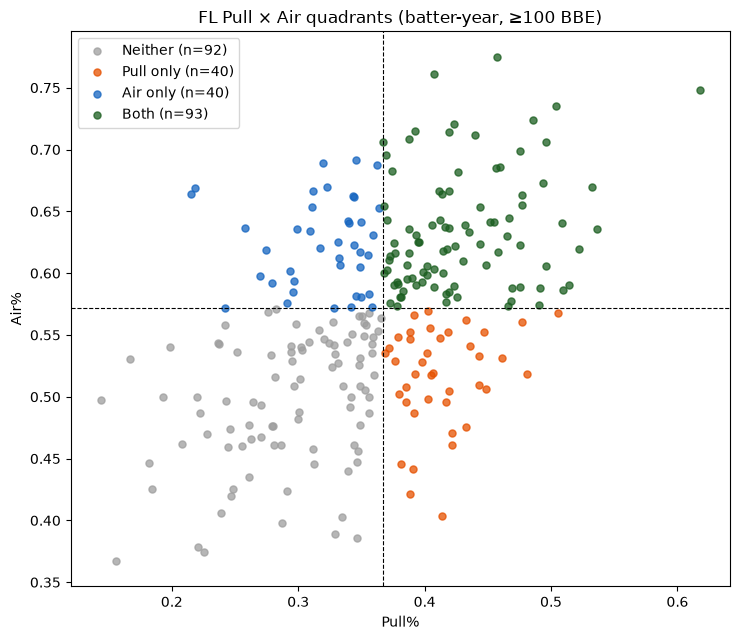

In [38]:
pull_cut = qual["pull_pct"].median()
air_cut  = qual["air_ball_pct"].median()

qual["is_pull_hitter"] = qual["pull_pct"]     >= pull_cut
qual["is_air_hitter"]  = qual["air_ball_pct"] >= air_cut

def quad(row):
    if row["is_pull_hitter"] and row["is_air_hitter"]:   return "Both"
    if row["is_pull_hitter"]:                            return "Pull only"
    if row["is_air_hitter"]:                             return "Air only"
    return "Neither"

qual["quadrant"] = qual.apply(quad, axis=1)

print(f"Median cuts — Pull%: {pull_cut:.3f}   Air%: {air_cut:.3f}\n")
print(qual["quadrant"].value_counts().reindex(QUAD_ORDER))

fig, ax = plt.subplots(figsize=(7.5, 6.5))
for q in QUAD_ORDER:
    sub = qual[qual["quadrant"] == q]
    ax.scatter(sub["pull_pct"], sub["air_ball_pct"], s=26, alpha=0.75,
               color=QUAD_COLORS[q], label=f"{q} (n={len(sub)})")
ax.axvline(pull_cut, color="black", lw=0.8, ls="--")
ax.axhline(air_cut,  color="black", lw=0.8, ls="--")
ax.set_xlabel("Pull%"); ax.set_ylabel("Air%")
ax.set_title(f"FL Pull × Air quadrants (batter-year, ≥{MIN_BBE} BBE)")
ax.legend(); plt.tight_layout(); plt.show()

## 7. Correlations — PAA & PAD vs the Marginals and the Joint

In [39]:
print("── Marginals & joint, batter-year level ──────────────────────────")
pairs = [("pull_pct", "air_ball_pct"), ("pull_pct", "pull_air_pct"),
         ("air_ball_pct", "pull_air_pct")]
for a, b in pairs:
    r_p, _ = stats.pearsonr(qual[a], qual[b])
    r_s, _ = spearmanr(qual[a], qual[b])
    print(f"  {a:>13} vs {b:<13}  Pearson {r_p:+.3f}   Spearman {r_s:+.3f}")

print("\n── PAA / PAD vs each rate ─────────────────────────────────────────")
print(f"{'Feature':<6} {'Target':<14} {'Pearson r':>10} {'Spearman ρ':>11} {'p':>10}")
print("-" * 56)
for feat in ["PAA", "PAD"]:
    for target in ["pull_pct", "air_ball_pct", "pull_air_pct"]:
        r_p, _   = stats.pearsonr(qual[feat], qual[target])
        r_s, p_s = spearmanr(qual[feat], qual[target])
        print(f"{feat:<6} {target:<14} {r_p:>10.4f} {r_s:>11.4f} {p_s:>10.2e}")

── Marginals & joint, batter-year level ──────────────────────────
       pull_pct vs air_ball_pct   Pearson +0.491   Spearman +0.461
       pull_pct vs pull_air_pct   Pearson +0.872   Spearman +0.872
   air_ball_pct vs pull_air_pct   Pearson +0.713   Spearman +0.689

── PAA / PAD vs each rate ─────────────────────────────────────────
Feature Target          Pearson r  Spearman ρ          p
--------------------------------------------------------
PAA    pull_pct           0.4137      0.4021   1.02e-11
PAA    air_ball_pct       0.6955      0.6908   6.37e-39
PAA    pull_air_pct       0.4906      0.4949   8.91e-18
PAD    pull_pct           0.6684      0.6401   5.92e-32
PAD    air_ball_pct       0.3338      0.3172   1.32e-07
PAD    pull_air_pct       0.6391      0.6158   4.67e-29


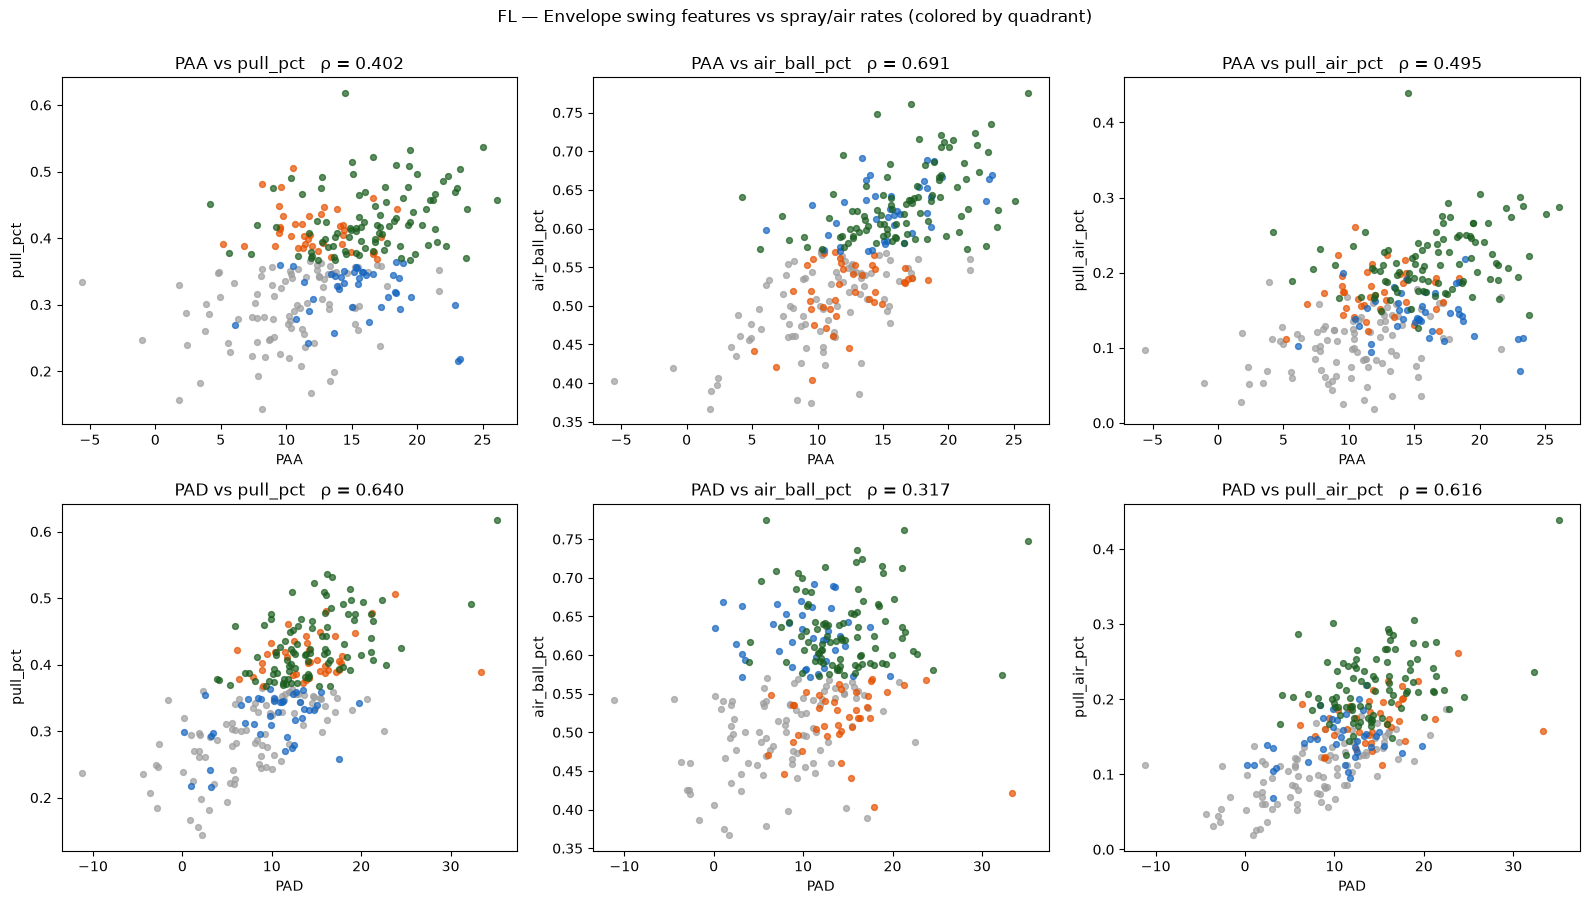

In [40]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for row, feat in enumerate(["PAA", "PAD"]):
    for col, target in enumerate(["pull_pct", "air_ball_pct", "pull_air_pct"]):
        ax = axes[row, col]
        for q in QUAD_ORDER:
            sub = qual[qual["quadrant"] == q]
            ax.scatter(sub[feat], sub[target], s=18, alpha=0.7,
                       color=QUAD_COLORS[q])
        r_s, _ = spearmanr(qual[feat], qual[target])
        ax.set_xlabel(feat); ax.set_ylabel(target)
        ax.set_title(f"{feat} vs {target}   ρ = {r_s:.3f}")
plt.suptitle("FL — Envelope swing features vs spray/air rates (colored by quadrant)", y=1.00)
plt.tight_layout(); plt.show()

## 8. Feature Profiles by Quadrant

             PAA    PAD  mean_ev   ev_90  hard_hit_pct  wOBAcon
quadrant                                                       
Neither   10.261  7.693   84.491  99.255         0.249    0.376
Pull only 12.219 14.352   86.237 101.478         0.317    0.391
Air only  15.537 10.035   86.093 100.323         0.286    0.405
Both      16.467 14.545   86.263 100.992         0.310    0.409


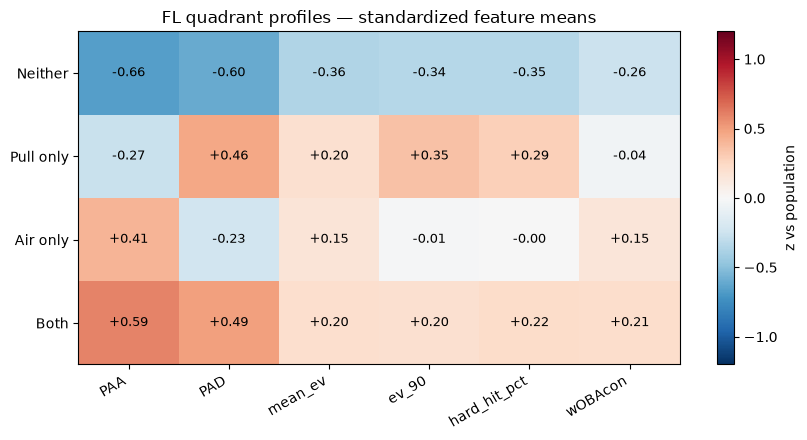

PAA: ANOVA F=39.40 (p=4.92e-21)   Kruskal H=89.09 (p=3.43e-19)
PAD: ANOVA F=29.51 (p=1.85e-16)   Kruskal H=68.02 (p=1.13e-14)


In [41]:
PROFILE_FEATS = ["PAA", "PAD", "mean_ev", "ev_90", "hard_hit_pct", "wOBAcon"]

feat_means = qual.groupby("quadrant")[PROFILE_FEATS].mean().reindex(QUAD_ORDER)
print(feat_means.round(3).to_string())

# Standardized (z) heatmap
z = (feat_means - qual[PROFILE_FEATS].mean()) / qual[PROFILE_FEATS].std()
fig, ax = plt.subplots(figsize=(8.5, 4.5))
im = ax.imshow(z.values, cmap="RdBu_r", vmin=-1.2, vmax=1.2, aspect="auto")
ax.set_xticks(range(len(PROFILE_FEATS))); ax.set_xticklabels(PROFILE_FEATS, rotation=30, ha="right")
ax.set_yticks(range(len(QUAD_ORDER)));    ax.set_yticklabels(QUAD_ORDER)
for i in range(z.shape[0]):
    for j in range(z.shape[1]):
        ax.text(j, i, f"{z.values[i,j]:+.2f}", ha="center", va="center",
                color="black", fontsize=9)
plt.colorbar(im, ax=ax, label="z vs population")
ax.set_title("FL quadrant profiles — standardized feature means")
plt.tight_layout(); plt.show()

# ANOVA / Kruskal: does the quadrant label separate PAA and PAD?
for feat in ["PAA", "PAD"]:
    groups = [qual.loc[qual["quadrant"] == q, feat].dropna() for q in QUAD_ORDER]
    f_stat, f_p = f_oneway(*groups)
    k_stat, k_p = kruskal(*groups)
    print(f"{feat}: ANOVA F={f_stat:.2f} (p={f_p:.2e})   Kruskal H={k_stat:.2f} (p={k_p:.2e})")

## 9. Multinomial Quadrant Classifiers

Feature set: **PAA, PAD, is_L, PAD × is_L** — the envelope analogs of the MLB build's
`mean_aa`, `mean_dir`, `is_L`, `mean_dir × is_L`. GroupKFold by batter (a batter's
2024 and 2025 rows never straddle train/validation).

In [42]:
qual["pad_x_isL"] = qual["PAD"] * qual["is_L"]

CLF_FEATS = ["PAA", "PAD", "is_L", "pad_x_isL"]

X      = qual[CLF_FEATS].to_numpy(dtype=np.float64)
y      = qual["quadrant"].to_numpy(dtype=object)
groups = qual["batter"].to_numpy(dtype=object)

n_splits = min(5, qual["batter"].nunique())
gkf = GroupKFold(n_splits=n_splits)

pipe_lr = Pipeline([("s", StandardScaler()),
                    ("m", LogisticRegression(max_iter=2000, multi_class="multinomial"))])
pipe_rf = Pipeline([("s", StandardScaler()),
                    ("m", RandomForestClassifier(n_estimators=400, min_samples_leaf=3,
                                                 random_state=42, n_jobs=-1))])

pred_lr = cross_val_predict(pipe_lr, X, y, cv=gkf, groups=groups)
pred_rf = cross_val_predict(pipe_rf, X, y, cv=gkf, groups=groups)

# Proportional baseline (guess by class frequency)
class_freq = pd.Series(y).value_counts(normalize=True)
prop_baseline = (class_freq ** 2).sum()

print(f"Proportional-guess baseline accuracy: {prop_baseline:.3f}\n")
for name, pred in [("Multinomial LR (+interaction)", pred_lr), ("Random Forest", pred_rf)]:
    acc = accuracy_score(y, pred)
    kap = cohen_kappa_score(y, pred)
    print(f"{name:<32}  accuracy {acc:.3f}   κ {kap:.3f}")

print("\n── Per-quadrant metrics (LR) ──")
rep = pd.DataFrame(classification_report(y, pred_lr, labels=QUAD_ORDER,
                                         output_dict=True, zero_division=0)).T
print(rep.loc[QUAD_ORDER, ["precision", "recall", "f1-score", "support"]].round(3).to_string())

Proportional-guess baseline accuracy: 0.289

Multinomial LR (+interaction)     accuracy 0.592   κ 0.383
Random Forest                     accuracy 0.570   κ 0.380

── Per-quadrant metrics (LR) ──
           precision  recall  f1-score  support
Neither        0.624   0.793     0.699   92.000
Pull only      0.286   0.050     0.085   40.000
Air only       0.667   0.100     0.174   40.000
Both           0.578   0.839     0.684   93.000


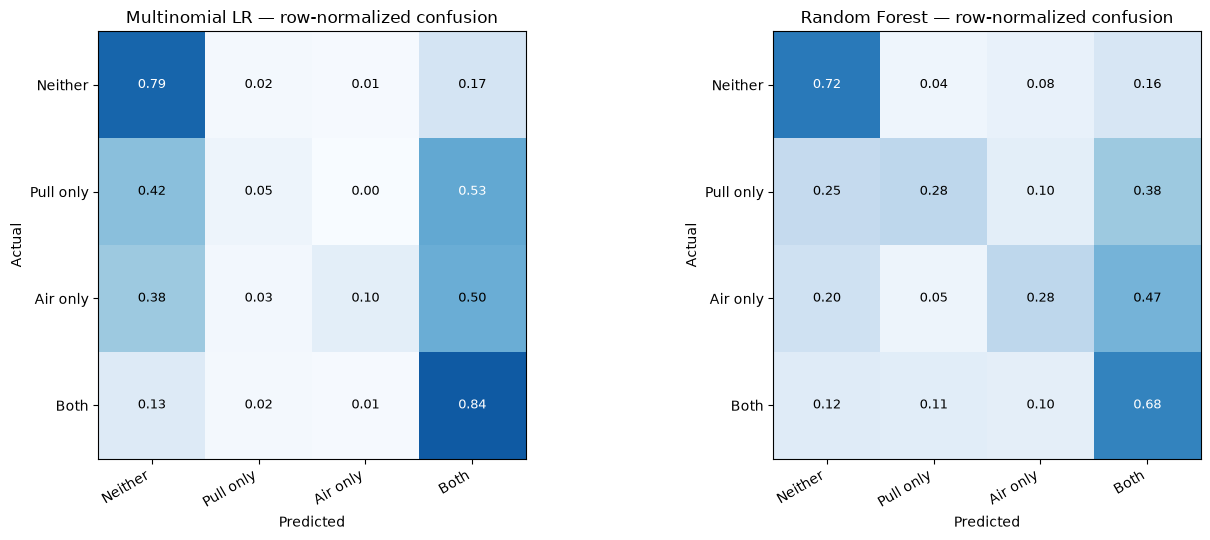

── Standardized LR coefficients (per quadrant, one-vs-rest direction) ──
             PAA    PAD   is_L  pad_x_isL
Air only   0.449 -0.503  0.023      0.227
Both       1.009  0.897  0.089     -0.124
Neither   -1.039 -0.883  0.203     -0.208
Pull only -0.420  0.489 -0.315      0.105


In [43]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (name, pred) in zip(axes, [("Multinomial LR", pred_lr), ("Random Forest", pred_rf)]):
    cm = confusion_matrix(y, pred, labels=QUAD_ORDER, normalize="true")
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(4)); ax.set_xticklabels(QUAD_ORDER, rotation=30, ha="right")
    ax.set_yticks(range(4)); ax.set_yticklabels(QUAD_ORDER)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{cm[i,j]:.2f}", ha="center", va="center",
                    color="white" if cm[i,j] > 0.5 else "black", fontsize=9)
    ax.set_title(f"{name} — row-normalized confusion")
    ax.set_ylabel("Actual"); ax.set_xlabel("Predicted")
plt.tight_layout(); plt.show()

# LR coefficients (fit on full data for interpretation)
pipe_lr.fit(X, y)
coefs = pd.DataFrame(pipe_lr.named_steps["m"].coef_,
                     index=pipe_lr.named_steps["m"].classes_, columns=CLF_FEATS)
print("── Standardized LR coefficients (per quadrant, one-vs-rest direction) ──")
print(coefs.round(3).to_string())

In [44]:
qual["pull_dist"] = (qual["pull_pct"] - pull_cut).abs()
qual["air_dist"]  = (qual["air_ball_pct"] - air_cut).abs()

for q in ["Pull only", "Air only"]:
    sub = qual[qual["quadrant"] == q]
    print(f"{q}: mean dist from pull cut = {sub['pull_dist'].mean():.3f}, "
          f"mean dist from air cut = {sub['air_dist'].mean():.3f}")

Pull only: mean dist from pull cut = 0.045, mean dist from air cut = 0.055
Air only: mean dist from pull cut = 0.049, mean dist from air cut = 0.052


In [45]:
r_p, _ = stats.pearsonr(qual["PAA"], qual["PAD"])
print(f"PAA vs PAD: r = {r_p:.3f}")

PAA vs PAD: r = 0.120


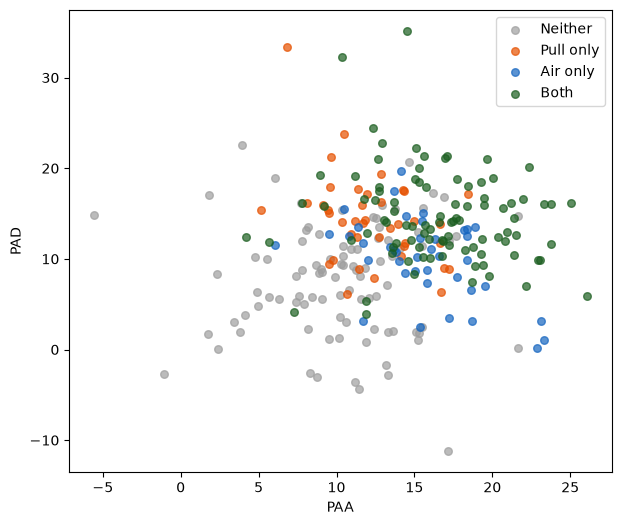

In [46]:
fig, ax = plt.subplots(figsize=(7,6))
for q in QUAD_ORDER:
    sub = qual[qual["quadrant"]==q]
    ax.scatter(sub["PAA"], sub["PAD"], color=QUAD_COLORS[q], label=q, s=30, alpha=0.7)
ax.set_xlabel("PAA"); ax.set_ylabel("PAD"); ax.legend()

## 10. Direct Pull Air% Regression

Approach-B analog: continuous ranking score from the envelope features.

Random Forest   R² 0.490   Spearman ρ 0.696
Linear          R² 0.557   Spearman ρ 0.729


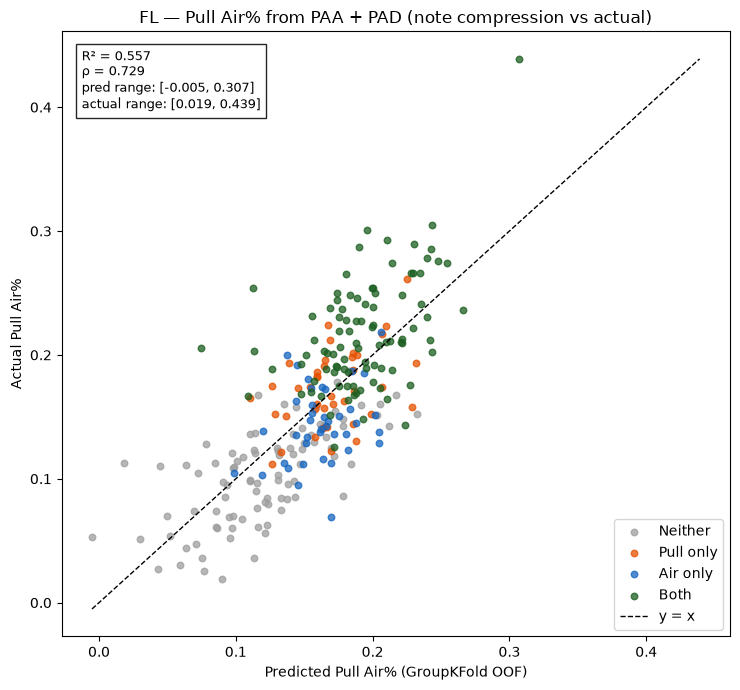

In [47]:
REG_FEATS = ["PAA", "PAD", "is_L", "pad_x_isL"]
Xr = qual[REG_FEATS].to_numpy(dtype=np.float64)
yr = qual["pull_air_pct"].to_numpy(dtype=np.float64)

pipe_reg = Pipeline([("s", StandardScaler()),
                     ("m", RandomForestRegressor(n_estimators=400, min_samples_leaf=3,
                                                 random_state=42, n_jobs=-1))])
pred_rf_reg = cross_val_predict(pipe_reg, Xr, yr, cv=gkf, groups=groups)

pipe_lin = Pipeline([("s", StandardScaler()), ("m", LinearRegression())])
pred_lin = cross_val_predict(pipe_lin, Xr, yr, cv=gkf, groups=groups)

for name, pred in [("Random Forest", pred_rf_reg), ("Linear", pred_lin)]:
    r2  = r2_score(yr, pred)
    r_s, _ = spearmanr(yr, pred)
    print(f"{name:<14}  R² {r2:.3f}   Spearman ρ {r_s:.3f}")

# Compression check (the MLB notebook's predicted-vs-actual diagnostic)
best_pred = pred_rf_reg if r2_score(yr, pred_rf_reg) >= r2_score(yr, pred_lin) else pred_lin
fig, ax = plt.subplots(figsize=(7.5, 7))
for q in QUAD_ORDER:
    m = qual["quadrant"].values == q
    ax.scatter(best_pred[m], yr[m], s=22, alpha=0.75, color=QUAD_COLORS[q], label=q)
lims = [min(best_pred.min(), yr.min()), max(best_pred.max(), yr.max())]
ax.plot(lims, lims, "k--", lw=1, label="y = x")
r2  = r2_score(yr, best_pred)
r_s, _ = spearmanr(yr, best_pred)
ax.text(0.03, 0.97,
        f"R² = {r2:.3f}\nρ = {r_s:.3f}\n"
        f"pred range: [{best_pred.min():.3f}, {best_pred.max():.3f}]\n"
        f"actual range: [{yr.min():.3f}, {yr.max():.3f}]",
        transform=ax.transAxes, va="top", fontsize=9,
        bbox=dict(facecolor="white", alpha=0.85))
ax.set_xlabel("Predicted Pull Air% (GroupKFold OOF)")
ax.set_ylabel("Actual Pull Air%")
ax.set_title("FL — Pull Air% from PAA + PAD (note compression vs actual)")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

## 11. wOBAcon by Quadrant (BBE-weighted, with error bars)

            n  wOBAcon_weighted  wOBAcon_simple   sem
quadrant                                             
Neither    92             0.375           0.376 0.006
Pull only  40             0.396           0.391 0.011
Air only   40             0.406           0.405 0.013
Both       93             0.406           0.409 0.007


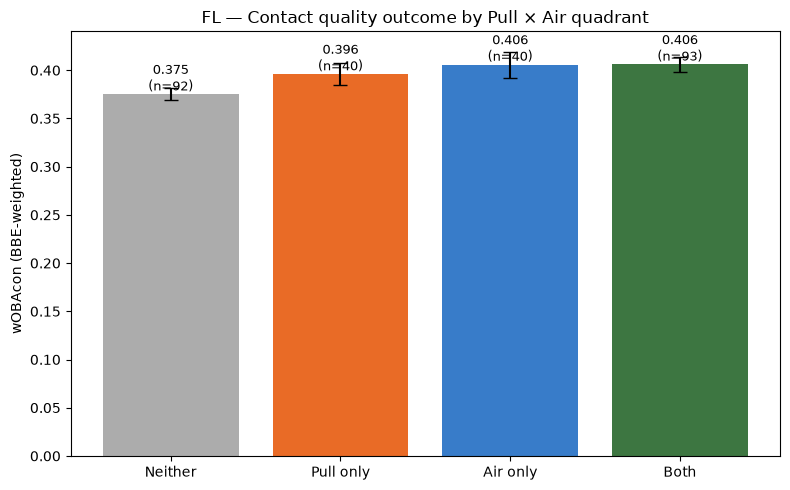

In [48]:
qd = qual.dropna(subset=["quadrant", "wOBAcon"]).copy()

rows = []
for q in QUAD_ORDER:
    sub = qd[qd["quadrant"] == q]
    w   = sub["n_bbe"]
    weighted = np.average(sub["wOBAcon"], weights=w)
    simple   = sub["wOBAcon"].mean()
    sem      = sub["wOBAcon"].std() / np.sqrt(len(sub))
    rows.append({"quadrant": q, "n": len(sub),
                 "wOBAcon_weighted": weighted, "wOBAcon_simple": simple, "sem": sem})
woba_tbl = pd.DataFrame(rows).set_index("quadrant")
print(woba_tbl.round(4).to_string())

fig, ax = plt.subplots(figsize=(8, 5))
xs = np.arange(4)
ax.bar(xs, woba_tbl["wOBAcon_weighted"],
       yerr=woba_tbl["sem"], capsize=5,
       color=[QUAD_COLORS[q] for q in QUAD_ORDER], alpha=0.85)
ax.set_xticks(xs); ax.set_xticklabels(QUAD_ORDER)
ax.set_ylabel("wOBAcon (BBE-weighted)")
ax.set_title("FL — Contact quality outcome by Pull × Air quadrant")
for x, (v, n) in enumerate(zip(woba_tbl["wOBAcon_weighted"], woba_tbl["n"])):
    ax.text(x, v + 0.004, f"{v:.3f}\n(n={n})", ha="center", fontsize=9)
plt.tight_layout(); plt.show()

## 12. Year-over-Year Stickiness

PullAir%, PAA, and PAD stickiness for batters qualified in consecutive seasons —
the FL analog of the MLB multi-season stickiness section. Also checks whether the
envelope metrics are *stickier* than the outcome rate they predict (they should be,
if they're capturing swing identity rather than results).

── 2025.0 → 2026.0   (n = 58 repeat batter-years) ──
   pull_air_pct   Pearson +0.772   Spearman +0.736   (p=4.83e-11)
   PAA            Pearson +0.794   Spearman +0.819   (p=3.74e-15)
   PAD            Pearson +0.691   Spearman +0.641   (p=5.83e-08)


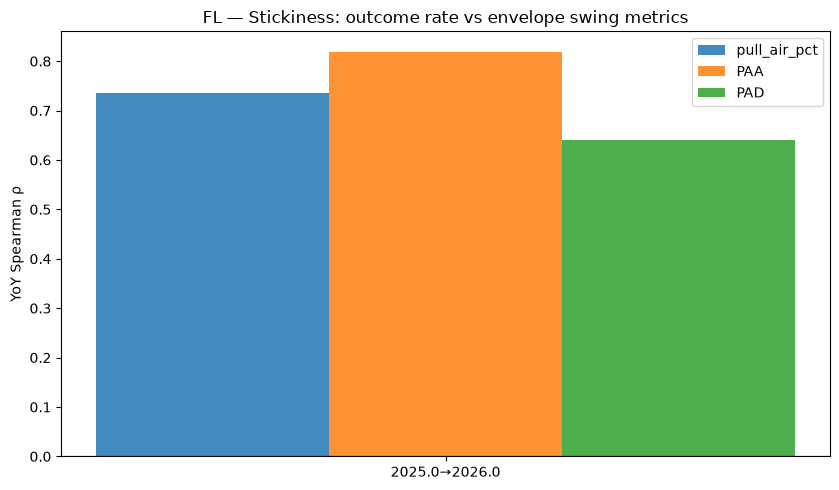

In [49]:
years = sorted(qual["year"].unique())
stick_rows = []
for y1, y2 in zip(years[:-1], years[1:]):
    a = qual[qual["year"] == y1][["batter", "pull_air_pct", "PAA", "PAD"]]
    b = qual[qual["year"] == y2][["batter", "pull_air_pct", "PAA", "PAD"]]
    m = a.merge(b, on="batter", suffixes=("_y1", "_y2"))
    if len(m) < 5:
        print(f"{y1}→{y2}: only {len(m)} repeaters — skipping")
        continue
    print(f"── {y1} → {y2}   (n = {len(m)} repeat batter-years) ──")
    for metric in ["pull_air_pct", "PAA", "PAD"]:
        r_s, p_s = spearmanr(m[f"{metric}_y1"], m[f"{metric}_y2"])
        r_p, _   = stats.pearsonr(m[f"{metric}_y1"], m[f"{metric}_y2"])
        stick_rows.append({"pair": f"{y1}→{y2}", "metric": metric,
                           "pearson": r_p, "spearman": r_s, "n": len(m)})
        print(f"   {metric:<14} Pearson {r_p:+.3f}   Spearman {r_s:+.3f}   (p={p_s:.2e})")

if stick_rows:
    stick_df = pd.DataFrame(stick_rows)
    fig, ax = plt.subplots(figsize=(8.5, 5))
    metrics = ["pull_air_pct", "PAA", "PAD"]
    pairs = stick_df["pair"].unique()
    w = 0.25
    for i, metric in enumerate(metrics):
        sub = stick_df[stick_df["metric"] == metric]
        ax.bar(np.arange(len(pairs)) + (i - 1) * w, sub["spearman"], width=w,
               label=metric, alpha=0.85)
    ax.set_xticks(range(len(pairs))); ax.set_xticklabels(pairs)
    ax.set_ylabel("YoY Spearman ρ")
    ax.set_title("FL — Stickiness: outcome rate vs envelope swing metrics")
    ax.axhline(0, color="black", lw=0.8)
    ax.legend(); plt.tight_layout(); plt.show()

## 13. Final Deliverable

In [50]:
out = qual[["batter", "year", "stand", "n_bbe",
            "pull_pct", "air_ball_pct", "pull_air_pct",
            "PAA", "PAD", "quadrant",
            "mean_ev", "ev_90", "hard_hit_pct", "wOBAcon"]].copy()
out["pred_pull_air_pct"] = best_pred
out = out.sort_values("pull_air_pct", ascending=False).reset_index(drop=True)

print("── Top 15 by Pull Air% ──")
print(out.head(15).to_string(index=False))

Path("output").mkdir(exist_ok=True)
out.to_csv("output/fl_pull_air_quadrants.csv", index=False)
print(f"\nSaved → output/fl_pull_air_quadrants.csv   ({len(out)} batter-years)")

── Top 15 by Pull Air% ──
             batter     year stand  n_bbe  pull_pct  air_ball_pct  pull_air_pct    PAA    PAD quadrant  mean_ev   ev_90  hard_hit_pct  wOBAcon  pred_pull_air_pct
      Curbelo, Luis 2025.000     R    123     0.618         0.748         0.439 14.529 35.151     Both   85.526 103.329         0.350    0.435              0.307
       Pino, Yassel 2025.000     R    272     0.496         0.706         0.305 20.025 18.906     Both   87.347 100.920         0.298    0.391              0.244
      Baker, Dillon 2026.000     R    103     0.476         0.699         0.301 23.059  9.877     Both   83.031  96.785         0.204    0.446              0.196
        Vogel, Ryan 2025.000     R    174     0.477         0.655         0.293 17.578 16.001     Both   76.848  93.143         0.057    0.346              0.211
      Scanlon, Jack 2025.000     L    121     0.504         0.736         0.289 23.288 16.064     Both   86.782  99.884         0.248    0.375              0.230
  

In [51]:
from sqlalchemy import bindparam

qual_batters = qual["batter"].unique().tolist()

SQL_PITCHES = text("""
    SELECT
        batter,
        year,
        pitch_call,
        k_or_bb,
        play_result,
        strikes
    FROM pitches
    WHERE batter IN :batter_list
""").bindparams(bindparam("batter_list", expanding=True))

with engine.connect() as conn:
    pitch_log = pd.read_sql(SQL_PITCHES, conn, params={"batter_list": qual_batters})

print(f"Pulled {len(pitch_log):,} pitch rows for {pitch_log['batter'].nunique()} batters")
print(pitch_log["pitch_call"].value_counts())
print(pitch_log["k_or_bb"].value_counts(dropna=False))

# ── PA-level outcome flags ──────────────────────────────────────────────────
# A PA ends on: strikeout, walk, hit-by-pitch, or any in-play result.
# Swings/whiffs are pitch-level; K% / BB% / contact rate need both.
pitch_log["is_swing"] = pitch_log["pitch_call"].isin(
    ["strike_swinging", "foul_not_fieldable", "foul_fieldable", "foul_ball", "in_play"]
)
pitch_log["is_whiff"]   = pitch_log["pitch_call"] == "strike_swinging"
pitch_log["is_contact"] = pitch_log["is_swing"] & ~pitch_log["is_whiff"]
pitch_log["is_hbp"]     = pitch_log["pitch_call"] == "hit_by_pitch"

pitch_log["is_k"]  = pitch_log["k_or_bb"] == "strikeout"
pitch_log["is_bb"] = pitch_log["k_or_bb"] == "walk"

pitch_log["is_pa_ending"] = (
    pitch_log["is_k"] | pitch_log["is_bb"] | pitch_log["is_hbp"] |
    (pitch_log["pitch_call"] == "in_play")
)
pitch_log.loc[pitch_log["is_hbp"], "pr_norm"] = "hit_by_pitch"

# ── wOBA weights (standard linear weights incl. walks) ──────────────────────
WOBA_W_FULL = {
    "walk": 0.69, "hit_by_pitch": 0.72,
    "single": 0.88, "double": 1.25, "triple": 1.58, "home_run": 2.03,
}
pitch_log["pr_norm"] = pitch_log["play_result"].astype(str).str.lower().str.replace(" ", "")
pitch_log.loc[pitch_log["is_bb"], "pr_norm"] = "walk"
pitch_log["woba_val_full"] = pitch_log["pr_norm"].map(WOBA_W_FULL).fillna(0.0)

# wOBA denominator: PA minus intentional walks/sac (approximated here as all PA)
pa_ending = pitch_log[pitch_log["is_pa_ending"]].copy()

# ── Aggregate to batter-year ─────────────────────────────────────────────────
perf = pitch_log.groupby(["batter", "year"]).agg(
    n_pitches   = ("pitch_call", "size"),
    n_swings    = ("is_swing",   "sum"),
    n_whiffs    = ("is_whiff",   "sum"),
    n_contact   = ("is_contact", "sum"),
).reset_index()

pa_agg = pa_ending.groupby(["batter", "year"]).agg(
    n_pa    = ("is_pa_ending", "sum"),
    n_k     = ("is_k",  "sum"),
    n_bb    = ("is_bb", "sum"),
    wOBA    = ("woba_val_full", "mean"),
).reset_index()

perf = perf.merge(pa_agg, on=["batter", "year"], how="left")
perf["k_pct"]        = perf["n_k"]  / perf["n_pa"]
perf["bb_pct"]       = perf["n_bb"] / perf["n_pa"]
perf["contact_pct"]  = perf["n_contact"] / perf["n_swings"]   # contact rate on swings

# ── Merge onto the quadrant table ────────────────────────────────────────────
quad_perf = qual.merge(
    perf[["batter", "year", "k_pct", "bb_pct", "contact_pct", "wOBA", "n_pa"]],
    on=["batter", "year"], how="left"
)

# ── Aggregate by quadrant (BBE-weighted where it makes sense) ───────────────
PERF_FEATS = ["k_pct", "bb_pct", "contact_pct", "wOBA"]

perf_by_quad = quad_perf.groupby("quadrant").apply(
    lambda g: pd.Series({
        "n": len(g),
        "k_pct":       np.average(g["k_pct"],       weights=g["n_pa"]),
        "bb_pct":      np.average(g["bb_pct"],      weights=g["n_pa"]),
        "contact_pct": np.average(g["contact_pct"], weights=g["n_pa"]),
        "wOBA":        np.average(g["wOBA"],        weights=g["n_pa"]),
    })
).reindex(QUAD_ORDER)

print(perf_by_quad.round(3).to_string())

Pulled 299,037 pitch rows for 207 batters
pitch_call
ball_called           109895
in_play                53592
strike_called          50475
foul_not_fieldable     48132
strike_swinging        29665
ball_in_dirt            2683
hit_by_pitch            1776
foul_fieldable          1301
undefined               1162
ball_intentional         341
automatic_ball             8
foul_ball                  7
Name: count, dtype: int64
k_or_bb
undefined    276609
strikeout     14057
walk           8371
Name: count, dtype: int64
               n  k_pct  bb_pct  contact_pct  wOBA
quadrant                                          
Neither   92.000  0.160   0.105        0.807 0.328
Pull only 40.000  0.171   0.095        0.770 0.332
Air only  40.000  0.181   0.110        0.777 0.340
Both      93.000  0.195   0.111        0.768 0.333


In [52]:
pitch_log["is_two_strike"] = pitch_log["strikes"] == 2  # adjust col name if different

two_strike_contact = (
    pitch_log[pitch_log["is_two_strike"] & pitch_log["is_swing"]]
    .merge(qual[["batter", "year", "quadrant"]], on=["batter", "year"])
    .groupby("quadrant")
    .agg(n_2k_swings=("is_swing", "size"), contact_2k=("is_contact", "mean"))
    .reindex(QUAD_ORDER)
)
print(two_strike_contact.round(3))

           n_2k_swings  contact_2k
quadrant                          
Neither          14886       0.809
Pull only         6043       0.774
Air only          6711       0.788
Both             16647       0.763


In [53]:
pitch_log["is_foul"] = pitch_log["pitch_call"].isin(["foul_not_fieldable", "foul_fieldable", "foul_ball"])

foul_rate = (
    pitch_log[pitch_log["is_contact"]]
    .merge(qual[["batter", "year", "quadrant"]], on=["batter", "year"])
    .groupby("quadrant")
    .agg(n_contact=("is_contact", "size"), foul_share=("is_foul", "mean"))
    .reindex(QUAD_ORDER)
)
print(foul_rate.round(3))

           n_contact  foul_share
quadrant                        
Neither        33114       0.474
Pull only      13513       0.448
Air only       13971       0.493
Both           34617       0.488


In [54]:
pitch_log["is_called_strike"] = pitch_log["pitch_call"] == "strike_called"

called_strike_rate = (
    pitch_log
    .merge(qual[["batter", "year", "quadrant"]], on=["batter", "year"])
    .groupby("quadrant")
    .agg(n_pitches=("pitch_call", "size"), called_strike_pct=("is_called_strike", "mean"))
    .reindex(QUAD_ORDER)
)
print(called_strike_rate.round(3))

           n_pitches  called_strike_pct
quadrant                               
Neither        91759              0.170
Pull only      38873              0.165
Air only       40385              0.164
Both          103788              0.171
